# StockNet 扩大实验：从候选数量到独立因子

本 notebook 只读取 `stocknet_flash_20261015_v2` 的归档，不调用模型。

这是一项在首轮零入库诊断后开展的**探索性扩展**。固定 50 股、原 11 项门槛、单边 0.1% 成本、5 日调仓与时间切分。E4 系统枚举；E5 三个种子各 1,000 次组合；E6 模型假设及局部变体；E7 按开发筛选期反馈进行三轮各 800 次搜索。不中途因成功而提前结束。

发现期：2012-09-04–2013-12-31；开发筛选期：2014–2015；留出期：2016-01-01–2017-09-01。方向只由发现期确定。先按发现期 IC 过滤，再回测开发筛选期；最终按开发夏普排序，以平均绝对截面秩相关 <0.7 去相关。全部入库因子冻结后才统一读取留出期表现；主组合固定使用排名前五个（不足五个则全部）。

扩大搜索增加过拟合风险。源股票池有幸存者/事后选样偏差，历史复权不是 point-in-time 数据；本结果不证明可交易 Alpha，也不能证明模型或 FSA 的因果贡献。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd()
EXPERIMENT = ROOT / 'artifacts/stocknet_flash_20261015_v2'
REPORT = json.loads((EXPERIMENT / 'report.json').read_text())
AUDIT = json.loads((EXPERIMENT / 'verification.json').read_text())
FIGURES = EXPERIMENT / 'figures'
FIGURES.mkdir(exist_ok=True)
assert REPORT['status'] == 'completed' and AUDIT['status'] == 'passed'
assert REPORT['budget']['cost_upper_bound_cny'] <= 40
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10,
                    'axes.spines.top': False, 'axes.spines.right': False,
                    'savefig.facecolor': 'white'})
counts = pd.DataFrame(REPORT['branches']).T
display(counts[['attempts', 'legal', 'backtested', 'quality_passed', 'accepted']])
print('Total attempts:', counts.attempts.sum())
print('Full selection backtests:', counts.backtested.sum())
print('Before correlation screen:', counts.quality_passed.sum())
print('Final admitted library:', counts.accepted.sum())


,attempts,legal,backtested,quality_passed,accepted
E0,6,6,6,0,0
E4,966,966,160,2,0
E5,3000,3000,265,0,0
E6,265,190,26,1,0
E7,2400,1311,509,133,23


Total attempts: 6637
Full selection backtests: 966
Before correlation screen: 136
Final admitted library: 23


## 全部尝试与最终入库

合法但重复、退化、发现期 IC 不足的表达式都留在尝试总数中。通过数值门槛的参数变体不等于不同因子；右图显示去相关后的数量。各分支规模和角色不同，共享候选库，不能据此作等预算优劣比较。


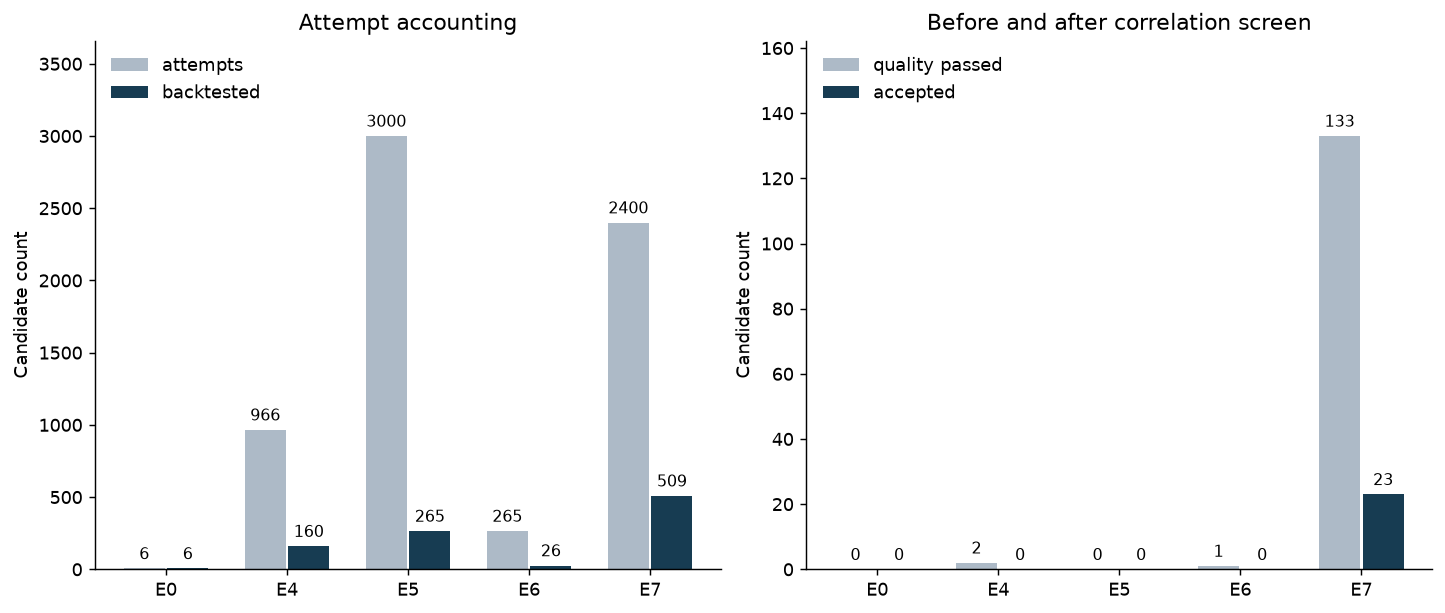

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
for ax, keys, title in [
    (axes[0], ['attempts', 'backtested'], 'Attempt accounting'),
    (axes[1], ['quality_passed', 'accepted'], 'Before and after correlation screen')]:
    x = np.arange(len(counts))
    for j, key in enumerate(keys):
        bars = ax.bar(x + (j - .5) * .36, counts[key].astype(int), width=.34,
                      color=['#adbac7', '#173c52'][j], label=key.replace('_', ' '))
        ax.bar_label(bars, padding=3, fontsize=9)
    ax.set(xticks=x, xticklabels=counts.index, ylabel='Candidate count', title=title)
    ax.margins(y=.22)
    ax.legend(frameon=False, loc='upper left')
fig.savefig(FIGURES / 'expanded-accounting.png', bbox_inches='tight')
plt.show()


## 开发筛选期与留出期

以下逐个展示所有入库因子，包括留出期收益为负的结果。两段时间的长度不同，年化超额采用相同口径；开发数据参与了大量搜索，不是样本外业绩。所有策略与等权基准均扣费，并在区间结束时平仓。


,Factor,Expression,Direction,Discovery IC,Selection Calmar,Selection annual excess,Holdout annual excess,Holdout Sharpe
0,E7-01156,"ts_mean(add(cs_rank(ts_corr(ret1, intraday_ret...",1,0.071776,3.459785,0.138116,-0.004277,-0.038556
1,E7-01310,"ts_mean(add(cs_rank(ts_mean(ts_corr(ret1, intr...",1,0.043003,3.888759,0.119257,-0.110770,-1.879525
2,E7-01980,"ts_mean(ts_mean(ts_mean(ts_corr(gap, upper_sha...",-1,0.044462,3.642581,0.106100,0.007342,0.166369
3,E7-00057,add(cs_rank(ts_mean(safe_div(ts_mean(intraday_...,1,0.052629,2.369411,0.099795,-0.024181,-0.422777
4,E7-00892,add(cs_rank(sub(cs_zscore(ts_mean(upper_shadow...,1,0.043698,2.398517,0.106089,-0.048524,-0.777769
5,E7-00948,"ts_mean(add(cs_rank(ts_corr(rel_volume, upper_...",1,0.031979,2.026043,0.087040,-0.098933,-1.871837
6,E7-00774,add(cs_rank(sub(cs_rank(ts_mean(intraday_range...,1,0.049709,2.022953,0.101252,-0.087856,-1.269861
7,E7-02224,"ts_mean(ts_mean(ts_mean(ts_corr(gap, upper_sha...",-1,0.056761,2.060087,0.080967,-0.016947,-0.267321
8,E7-00984,ts_mean(add(cs_rank(ts_mean(ts_corr(rel_volume...,1,0.050938,1.323019,0.086633,-0.045985,-0.791689
9,E7-00764,"add(cs_rank(neg(ts_mean(ts_corr(gap, upper_sha...",1,0.051241,1.443688,0.077254,-0.034774,-0.583311


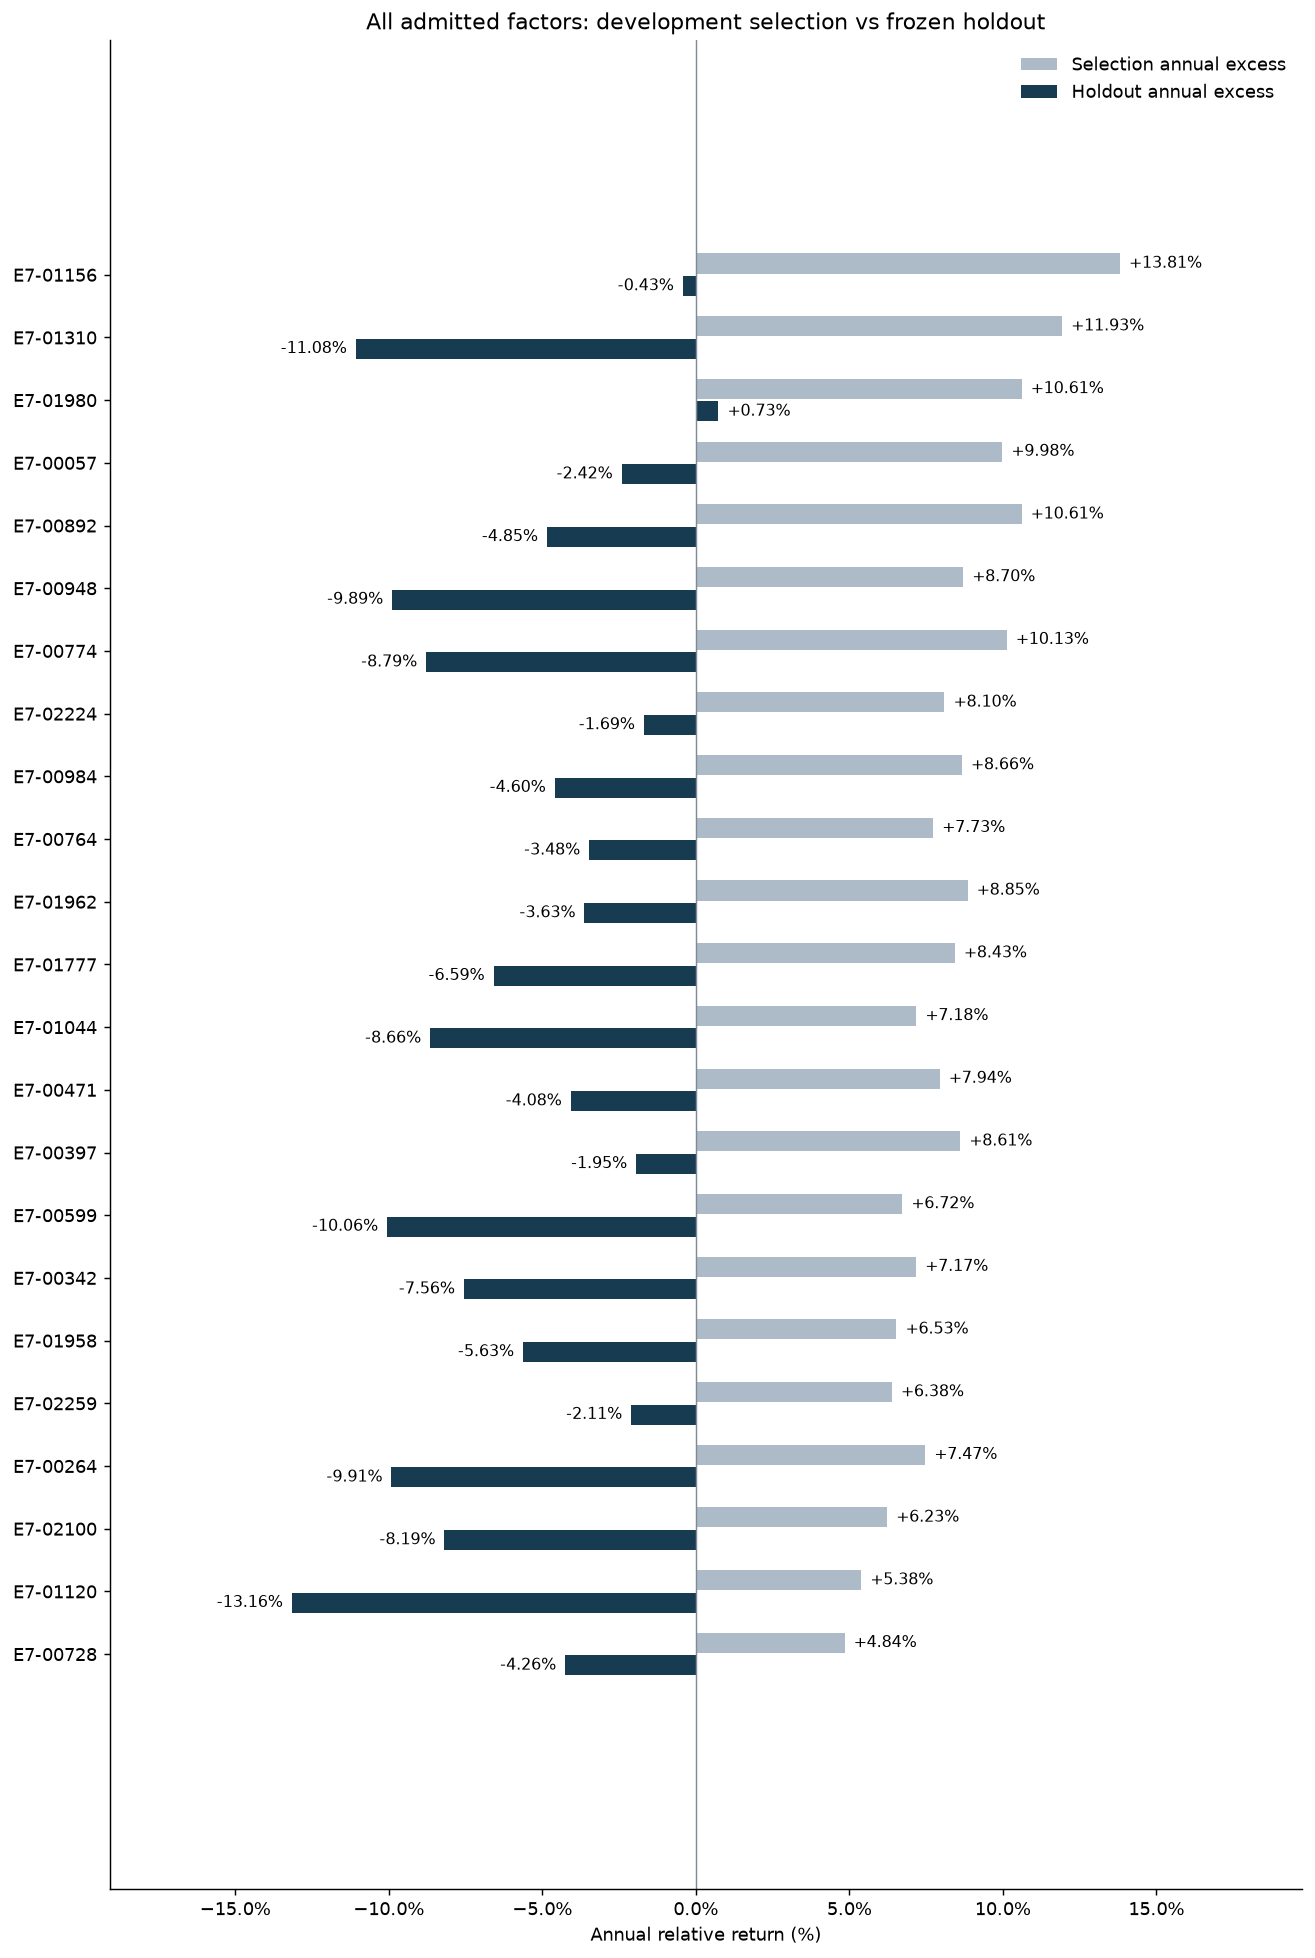

,annual_excess,sharpe,max_drawdown,calmar,factor_count
Frozen top-five rank blend,-0.031759,-0.508971,-0.090918,-0.349314,5


In [3]:
rows = []
test = {f['id']: f for f in REPORT['holdout']['LIBRARY']['factors']}
for f in REPORT['accepted_factors']:
    rows.append({'Factor': f['id'], 'Expression': f['expression'], 'Direction': f['direction'],
                 'Discovery IC': f['discovery_ic'], 'Selection Calmar': f['metrics']['calmar'],
                 'Selection annual excess': f['periods']['selection']['annual_excess'],
                 'Holdout annual excess': test[f['id']]['annual_excess'],
                 'Holdout Sharpe': test[f['id']]['sharpe']})
factors = pd.DataFrame(rows)
display(factors)
factors.to_csv(EXPERIMENT / 'accepted-factors.csv', index=False)
fig, ax = plt.subplots(figsize=(10, max(4.5, len(factors) * .65)), layout='constrained')
y = np.arange(len(factors))
for j, key, color in [(0, 'Selection annual excess', '#adbac7'),
                      (1, 'Holdout annual excess', '#173c52')]:
    values = factors[key].to_numpy() * 100
    bars = ax.barh(y + (j - .5) * .36, values, height=.32, label=key, color=color)
    ax.bar_label(bars, labels=[f'{v:+.2f}%' for v in values], padding=5, fontsize=9)
ax.set(yticks=y, yticklabels=factors.Factor, xlabel='Annual relative return (%)',
       title='All admitted factors: development selection vs frozen holdout')
ax.invert_yaxis()
ax.axvline(0, linewidth=.8, color='#808b97')
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.margins(x=.22, y=.15)
ax.legend(frameon=False)
fig.savefig(FIGURES / 'selection-vs-holdout.png', bbox_inches='tight')
plt.show()
display(pd.DataFrame([REPORT['holdout']['TOP5']['composite']], index=['Frozen top-five rank blend']))


## 费用与独立复核

账本跨实验共用，重试及未知结果保留预留额，40 元为累计上限。保守费用将所有 token 均按最高输出单价计算。usage 高峰价估算与账户余额差额另存 `billing.json`；后者精度为分，可能受账户其他活动影响。

独立 SciPy Spearman 与标量持仓账本/Brent 费用求解器已检查六个基线及全部入库因子：发现期 IC、开发和留出净值、门槛、去相关与组合。完整代码快照、数据 hash、冻结清单和逐条失败结果保存在实验目录。


In [4]:
display(pd.DataFrame([REPORT['budget']]))
display(pd.DataFrame([{k: AUDIT[k] for k in [
    'accepted_count', 'max_ic_absolute_error', 'max_nav_absolute_error',
    'max_metric_absolute_error', 'max_correlation_absolute_error',
    'peak_price_usage_estimate_cny', 'tokens']}]))
assert sum(b['accepted'] for b in REPORT['branches'].values()) == len(rows)
assert AUDIT['max_ic_absolute_error'] < 1e-10
assert AUDIT['max_nav_absolute_error'] < 1e-10
print('Freeze SHA-256:', REPORT['freeze_sha256'])
print('Protocol SHA-256:', REPORT['protocol_sha256'])


,requests,tokens_charged_or_reserved,cost_upper_bound_cny,unresolved_requests,hard_cap_cny,pricing_source,pricing_basis,run_requests,run_tokens,run_cost_upper_bound_cny,replayed_responses
0,50,44836,0.358688,0,40.0,https://api-docs.deepseek.com/zh-cn/quick_star...,all tokens at peak output price 8 CNY/million;...,10,12520,0.10016,0


,accepted_count,max_ic_absolute_error,max_nav_absolute_error,max_metric_absolute_error,max_correlation_absolute_error,peak_price_usage_estimate_cny,tokens
0,23,4.994338e-13,5.000000e-12,3.872458e-13,1.110223e-16,0.059396,12520


Freeze SHA-256: 31c6380dd5303d0a9e4de750d3b86a608d485e5eb4e3bb086fa9f2c17cc079ac
Protocol SHA-256: f5707ddcd7609ba32f6c007133f0d2863b2112264265b59dd857374055cf8bb7
